### Load raw dataset

In [65]:
import sqlite3
import pandas as pd

conn = sqlite3.connect("wildfire_data.sqlite")

# Load raw data set
relevant_columns = [
    'fire_name',
    'fire_year',
    'discovery_date',
    'discovery_doy',
    'discovery_time',
    'nwcg_cause_classification',
    'nwcg_general_cause',
    'nwcg_cause_age_category',
    'cont_date',
    'cont_doy',
    'cont_time',
    'fire_size',
    'fire_size_class',
    'latitude',
    'longitude',
    'upper(state) as state'
]

query = f"SELECT {', '.join(relevant_columns)} FROM FIRES WHERE fire_name IS NULL OR fire_name != 'ZION 3'"

try:
    raw_data = pd.read_sql_query(query, conn)
    raw_data.columns = raw_data.columns.str.lower()
finally:
    conn.close()

raw_data.shape
raw_data.head()

,fire_name,fire_year,discovery_date,discovery_doy,discovery_time,nwcg_cause_classification,nwcg_general_cause,nwcg_cause_age_category,cont_date,cont_doy,cont_time,fire_size,fire_size_class,latitude,longitude,state
0,FOUNTAIN,2005,2453403.5,33,1300,Human,Power generation/transmission/distribution,None,2453403.5,33.0,1730,0.10,A,40.036944,-121.005833,CA
1,PIGEON,2004,2453137.5,133,0845,Natural,Natural,None,2453137.5,133.0,1530,0.25,A,38.933056,-120.404444,CA
2,SLACK,2004,2453156.5,152,1921,Human,Debris and open burning,None,2453156.5,152.0,2024,0.10,A,38.984167,-120.735556,CA
3,DEER,2004,2453184.5,180,1600,Natural,Natural,None,2453189.5,185.0,1400,0.10,A,38.559167,-119.913333,CA
4,STEVENOT,2004,2453184.5,180,1600,Natural,Natural,None,2453189.5,185.0,1200,0.10,A,38.559167,-119.933056,CA


### Convert dates to standard format

In [66]:
def add_datetime(df, date_col, time_col, new_col):
    # Julian date -> datetime (midnight of that day)
    dates = pd.to_datetime(df[date_col], unit="D", origin="julian")

    # HHMM -> hours and minutes (to_numeric handles '0845' strings and NaNs)
    t = pd.to_numeric(df[time_col], errors="coerce")
    offset = pd.to_timedelta(t // 100, unit="h") + pd.to_timedelta(t % 100, unit="m")

    df[new_col] = dates + offset
    return df

raw_data = add_datetime(raw_data, "discovery_date", "discovery_time", "discovery_dt")
raw_data = add_datetime(raw_data, "cont_date", "cont_time", "cont_dt")

raw_data = raw_data.drop(columns=["discovery_date", "discovery_doy", "discovery_time", "cont_date", "cont_doy", "cont_time"])

raw_data["duration_hours"] = (
    raw_data["cont_dt"] - raw_data["discovery_dt"]
).dt.total_seconds() / 3600

raw_data.head()

,fire_name,fire_year,nwcg_cause_classification,nwcg_general_cause,nwcg_cause_age_category,fire_size,fire_size_class,latitude,longitude,state,discovery_dt,cont_dt,duration_hours
0,FOUNTAIN,2005,Human,Power generation/transmission/distribution,None,0.10,A,40.036944,-121.005833,CA,2005-02-02 13:00:00,2005-02-02 17:30:00,4.50
1,PIGEON,2004,Natural,Natural,None,0.25,A,38.933056,-120.404444,CA,2004-05-12 08:45:00,2004-05-12 15:30:00,6.75
2,SLACK,2004,Human,Debris and open burning,None,0.10,A,38.984167,-120.735556,CA,2004-05-31 19:21:00,2004-05-31 20:24:00,1.05
3,DEER,2004,Natural,Natural,None,0.10,A,38.559167,-119.913333,CA,2004-06-28 16:00:00,2004-07-03 14:00:00,118.00
4,STEVENOT,2004,Natural,Natural,None,0.10,A,38.559167,-119.933056,CA,2004-06-28 16:00:00,2004-07-03 12:00:00,116.00


### Drop Unknown Ignitions

In [67]:
print(raw_data['nwcg_cause_classification'].unique())
print(raw_data.shape)
raw_data = raw_data[raw_data['nwcg_cause_classification'] != 'Missing data/not specified/undetermined']
print(raw_data.shape)
print(raw_data['nwcg_cause_classification'].unique())


['Human' 'Natural' 'Missing data/not specified/undetermined']
(2661381, 13)
(2390585, 13)
['Human' 'Natural']


### Load GACC boundaries and add region column

In [68]:
keep_states = {
    "AL","AZ","AR","CA","CO","CT","DE","DC","FL","GA","ID","IL","IN","IA","KS",
    "KY","LA","ME","MD","MA","MI","MN","MS","MO","MT","NE","NV","NH","NJ","NM",
    "NY","NC","ND","OH","OK","OR","PA","RI","SC","SD","TN","TX","UT","VT","VA",
    "WA","WV","WI","WY","AK",
}

n0 = len(raw_data)
raw_data = raw_data[raw_data["state"].isin(keep_states)].copy()
print(f"Dropped {n0 - len(raw_data):,} fires outside AK + lower 48")

Dropped 714 fires outside AK + lower 48


In [69]:
import geopandas as gpd

# clean up gacc names to remove uneeded parts of the label
def clean_gacc(s):
    s = s.str.replace(
        r"\s*(Geographic Area|Interagency|Area)?\s*Coordination Center$",
        "", regex=True
    ).str.strip()
    return s.replace({"Eastern": "Eastern Area", "Southern": "Southern Area"})

# Load the boundaries, clean the names, then drop the islands:
gacc = gpd.read_file("gacc_boundaries.geojson")
gacc.columns = gacc.columns.str.lower()
gacc = gacc[["gaccname", "geometry"]].copy()
gacc["gaccname"] = clean_gacc(gacc["gaccname"])      # must come before the Alaska test below

parts = gacc.explode(index_parts=False)
pt = parts.geometry.representative_point()
keep = pt.x.between(-130, -60) & pt.y.between(24, 50)
gacc = parts[keep | (parts["gaccname"] == "Alaska")].dissolve(by="gaccname").reset_index()

print(sorted(gacc["gaccname"].unique()))   # 10 regions
print(gacc.total_bounds)

['Alaska', 'Eastern Area', 'Great Basin', 'Northern California', 'Northern Rockies', 'Northwest', 'Rocky Mountain', 'Southern Area', 'Southern California', 'Southwest']
[-179.23110125   24.3963123   179.85966573   71.43978571]


In [70]:
# Build points and join to fire dataset
fires = gpd.GeoDataFrame(
    raw_data,
    geometry=gpd.points_from_xy(raw_data["longitude"], raw_data["latitude"]),
    crs="EPSG:4326",
).to_crs(gacc.crs)

n_points = len(fires)
fires = gpd.sjoin(fires, gacc, how="left", predicate="within")

print(n_points, len(fires))                  # equal = no duplicated rows
print(fires["gaccname"].isna().sum())        # border fires, handled next

2389871 2390071
27


In [71]:
# Fires that didn't land in any GACC (offshore, bad coordinates, territories)
print(fires["gaccname"].isna().sum())

# sjoin can duplicate rows if a point touches overlapping polygons
print(len(raw_data), len(fires))

27
2389871 2390071


In [72]:
unmatched = fires[fires["gaccname"].isna()]
print(unmatched[["fire_name", "fire_year", "state", "latitude", "longitude"]])
print(unmatched["state"].value_counts())

              fire_name  fire_year state   latitude   longitude
24100             LUCKY       2007    AZ  31.333056 -110.639444
25726             YAQUI       2007    AZ  31.333333 -110.320833
156200    SCHOOL CANYON       2003    AZ  31.333056 -110.390278
172077         MARIPOSA       2004    AZ  31.332500 -110.983056
213138        MEXICO #2       1994    AZ  31.334300 -109.786700
240120           CANE 3       1994    TX  29.209800 -102.890150
308805        COUNTY 19       2001    AZ  32.566400 -114.792700
308881            LEVEE       2005    AZ  32.691400 -114.734400
308916       WALKING EA       2005    AZ  32.700000 -114.730000
308926            T BOB       2005    AZ  32.512000 -114.803000
713687      ST. FRANCIS       1993    ME  47.183334  -68.883331
1062928          TECATE       2009    AZ  31.951100 -113.051900
1065025         LETTUCE       2003    AZ  32.592000 -114.799700
1177054             105       2010    AZ  31.333056 -110.366667
1214685            LINE       2010    AZ

28 fires located on the international border fell outside GACC polygons and are assigned to the nearest GACC.

In [73]:
# Reproject to a metric CRS so distances are in meters, not degrees
gacc_m = gacc.to_crs("EPSG:5070")
unmatched = fires[fires["gaccname"].isna()].drop(columns=["gaccname", "index_right"])
unmatched_m = unmatched.to_crs("EPSG:5070")

nearest = gpd.sjoin_nearest(
    unmatched_m,
    gacc_m[["gaccname", "geometry"]],
    how="left",
    distance_col="dist_m",
)

# A point equidistant from two polygons returns two rows, so dedupe
nearest = nearest[~nearest.index.duplicated(keep="first")]

# Sanity check: these should all be small
print(nearest["dist_m"].describe())

# Write the matches back into the main frame
fires.loc[nearest.index, "gaccname"] = nearest["gaccname"]
print(fires["gaccname"].isna().sum())   # should be 0

count    27.000000
mean     19.870945
std      21.630126
min       0.559997
25%       4.613275
50%      13.418626
75%      26.636272
max      93.617059
Name: dist_m, dtype: float64
0


In [74]:
# drop bad rows with placeholder coordinates
bad = (
    (fires["state"] == "MO") & (fires["gaccname"] == "Southern Area")
    & (fires["latitude"] % 1 == 0) & (fires["longitude"] % 1 == 0)
)
print(bad.sum())   # expect 2
fires = fires[~bad].copy()

2


#### Visualize GACC boundaries and fires

In [75]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt


regions = sorted(gacc["gaccname"].unique())
colors = dict(zip(regions, plt.cm.tab10.colors))

CRS_US = "EPSG:5070"
CRS_AK = "EPSG:3338"

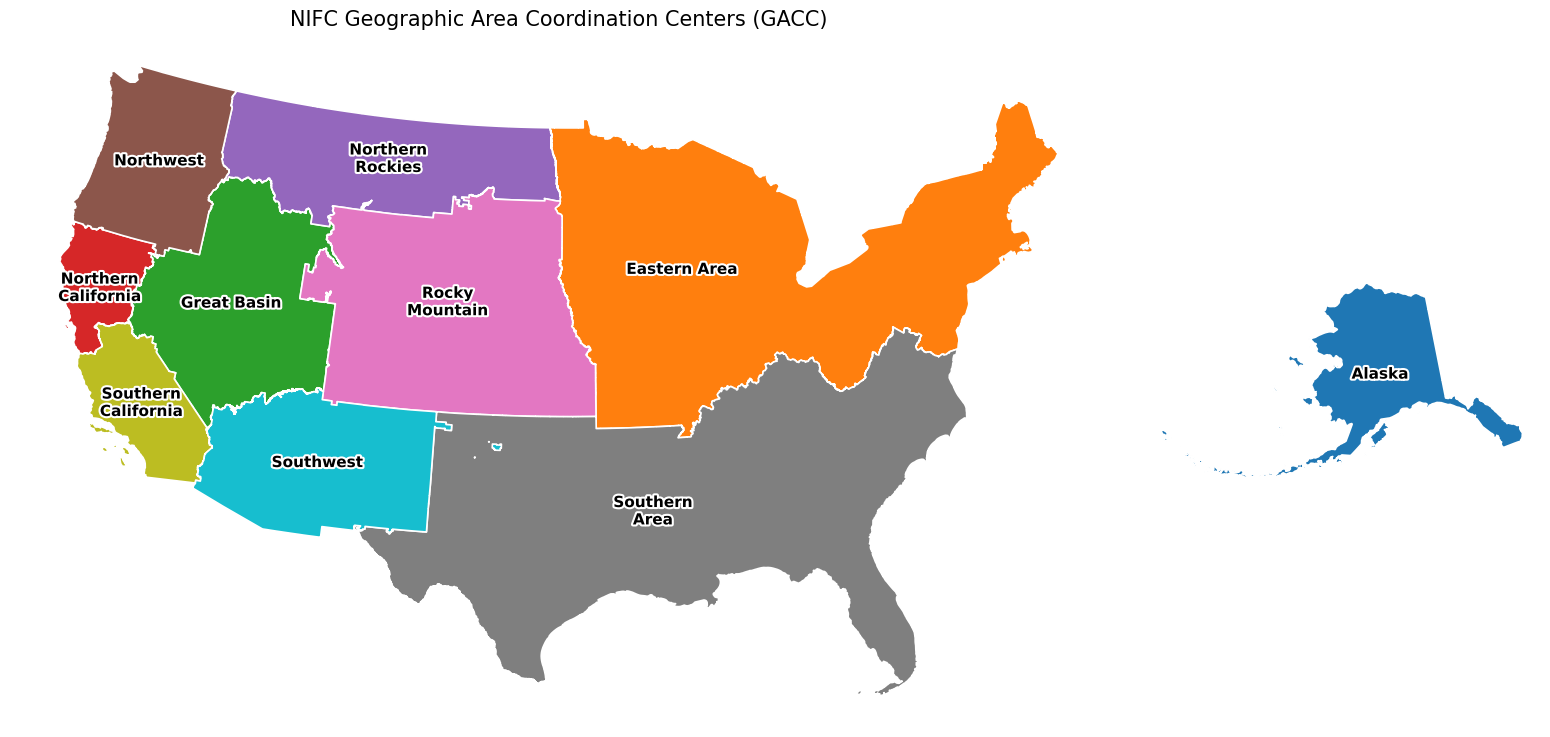

In [76]:
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

regions = sorted(gacc["gaccname"].unique())
colors = dict(zip(regions, plt.cm.tab10.colors))

lower48 = gacc[gacc["gaccname"] != "Alaska"].to_crs("EPSG:5070")
alaska  = gacc[gacc["gaccname"] == "Alaska"].to_crs("EPSG:3338")

fig = plt.figure(figsize=(20, 9))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1.4], wspace=0.02)
ax_main = fig.add_subplot(gs[0])
ax_ak   = fig.add_subplot(gs[1])

def draw(ax, g, fontsize):
    g.plot(ax=ax, color=g["gaccname"].map(colors), edgecolor="white", linewidth=1.2)
    for _, row in g.iterrows():
        p = row.geometry.representative_point()
        ax.annotate(
            row["gaccname"].replace(" ", "\n", 1) if len(row["gaccname"]) > 12 else row["gaccname"],
            (p.x, p.y), ha="center", va="center",
            fontsize=fontsize, fontweight="bold", color="black",
            path_effects=[pe.withStroke(linewidth=3, foreground="white")],
        )
    ax.set_axis_off()

draw(ax_main, lower48, fontsize=11)
draw(ax_ak, alaska, fontsize=11)

ax_main.set_title("NIFC Geographic Area Coordination Centers (GACC)", fontsize=15)
plt.savefig("gacc_regions.png", dpi=200, bbox_inches="tight")
plt.show()

The small bit of Southwest blue in the Southern area in not an error, it is the national grasslands in Texas and Omaha Panhandles that the Southwest Agency is in charge of.

In [77]:
'''
# Recompute after the filtering, so the color scale reflects the current data
fires["log_size"] = np.log10(fires["fire_size"].clip(lower=0.01))
vmin, vmax = fires["log_size"].min(), fires["log_size"].max()

# Sort once so the biggest fires are drawn last, on top
fires_sorted = fires.sort_values("fire_size")

# Split and project each part once
is_ak = fires_sorted["gaccname"] == "Alaska"
pts_main = fires_sorted[~is_ak].to_crs("EPSG:5070")
pts_ak   = fires_sorted[is_ak].to_crs("EPSG:3338")

poly_main = gacc[gacc["gaccname"] != "Alaska"].to_crs("EPSG:5070")
poly_ak   = gacc[gacc["gaccname"] == "Alaska"].to_crs("EPSG:3338")

fig = plt.figure(figsize=(22, 10))
gs = fig.add_gridspec(1, 2, width_ratios=[4, 1.4], wspace=0.02)
ax_main = fig.add_subplot(gs[0])
ax_ak   = fig.add_subplot(gs[1])

for ax, poly, pts, size in [
    (ax_main, poly_main, pts_main, 0.3),
    (ax_ak,   poly_ak,   pts_ak,   0.6),
]:
    poly.plot(ax=ax, color="#eeeeee", edgecolor="none")            # base fill
    pts.plot(ax=ax, column="log_size", cmap="viridis",
             vmin=vmin, vmax=vmax, markersize=size, alpha=0.6,
             rasterized=True)                                       # fires
    poly.boundary.plot(ax=ax, color="black", linewidth=0.8)         # borders on top
    ax.set_axis_off()

ax_main.set_title("Wildfires by GACC region (color = log10 acres burned)", fontsize=15)

sm = plt.cm.ScalarMappable(cmap="viridis", norm=plt.Normalize(vmin, vmax))
fig.colorbar(sm, ax=[ax_main, ax_ak], shrink=0.6, pad=0.01).set_label("log10(fire size, acres)")

plt.savefig("fires_by_region.png", dpi=200, bbox_inches="tight")
plt.show()
'''

'\n# Recompute after the filtering, so the color scale reflects the current data\nfires["log_size"] = np.log10(fires["fire_size"].clip(lower=0.01))\nvmin, vmax = fires["log_size"].min(), fires["log_size"].max()\n\n# Sort once so the biggest fires are drawn last, on top\nfires_sorted = fires.sort_values("fire_size")\n\n# Split and project each part once\nis_ak = fires_sorted["gaccname"] == "Alaska"\npts_main = fires_sorted[~is_ak].to_crs("EPSG:5070")\npts_ak   = fires_sorted[is_ak].to_crs("EPSG:3338")\n\npoly_main = gacc[gacc["gaccname"] != "Alaska"].to_crs("EPSG:5070")\npoly_ak   = gacc[gacc["gaccname"] == "Alaska"].to_crs("EPSG:3338")\n\nfig = plt.figure(figsize=(22, 10))\ngs = fig.add_gridspec(1, 2, width_ratios=[4, 1.4], wspace=0.02)\nax_main = fig.add_subplot(gs[0])\nax_ak   = fig.add_subplot(gs[1])\n\nfor ax, poly, pts, size in [\n    (ax_main, poly_main, pts_main, 0.3),\n    (ax_ak,   poly_ak,   pts_ak,   0.6),\n]:\n    poly.plot(ax=ax, color="#eeeeee", edgecolor="none")         

### Mann-Whitney Statistical Testing

In [79]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

summary = fires.groupby("nwcg_cause_classification")["fire_size"].agg(
    n="size", median="median", mean="mean", max="max",
    p75=lambda s: s.quantile(0.75), p95=lambda s: s.quantile(0.95),
)
print(summary)

                                 n  median        mean        max  p75     p95
nwcg_cause_classification                                                     
Human                      2033676     1.0   35.469152  1054153.0  3.0   40.00
Natural                     356393     0.2  337.056631   606945.0  2.0  159.84


In [ ]:
summary = fires.groupby(["nwcg_cause_classification", "fire_size_class"])["fire_size"].agg(
    n="size", median="median", mean="mean", max="max",
    p75=lambda s: s.quantile(0.75), p95=lambda s: s.quantile(0.95),
)
print(summary)

                                                 n    median          mean  \
nwcg_cause_classification fire_size_class                                    
Human                     A                 718860      0.10      0.115420   
                          B                1040549      1.00      2.086952   
                          C                 227781     20.00     28.367154   
                          D                  27404    150.00    161.232992   
                          E                  12107    457.00    506.043895   
                          F                   5225   1700.00   2027.980899   
                          G                   1750  10522.00  24157.380434   
Natural                   A                 193176      0.10      0.112120   
                          B                 109559      1.00      2.013746   
                          C                  31816     25.00     32.234953   
                          D                   7845    156.00    

In [81]:
def mwu(data, alt="two-sided"):
    human = data.loc[data["nwcg_cause_classification"] == "Human", "fire_size"].to_numpy()
    natural = data.loc[data["nwcg_cause_classification"] == "Natural", "fire_size"].to_numpy()
    
    result = mannwhitneyu(human, natural, alternative=alt)
    r = 2 * result.statistic / (len(human) * len(natural)) - 1 # rank-biserial

    return pd.Series({
        "n_human": len(human),
        "n_natural": len(natural),
        "median_human": np.median(human),
        "median_natural": np.median(natural),
        "U": result.statistic,
        "p_value": result.pvalue,
        "r_rb": r,  # The rank-biserial rescales the U statistic from -1 to 1 to determine which direction the fire cause leans -1 Natural to 1 Human
        "prob_superiority": (r + 1) / 2 # The prob_superiority calculates the probability of a randomly slected human fire to be larger than a randomly selected natural fire
        })

In [82]:
national = mwu(fires)
print("National Analysis")
print(national)

regional = pd.DataFrame({name: mwu(g) for name, g in fires.groupby("gaccname")}).T


ALPHA, R_MIN = 0.005, 0.10
regional["significant"] = regional["p_value"] < ALPHA
regional["meaningful"]  = regional["r_rb"].abs() >= R_MIN
regional["conclusion"] = np.where(
    regional["significant"] & regional["meaningful"],
    np.where(regional["r_rb"] > 0, "Human larger", "Natural larger"),
    "No meaningful difference",
)

print("\nRegional Analysis")
print(regional[["n_human", "n_natural", "median_human", "median_natural",
                "p_value", "r_rb", "conclusion"]])


National Analysis
n_human             2.033676e+06
n_natural           3.563930e+05
median_human        1.000000e+00
median_natural      2.000000e-01
U                   4.202637e+11
p_value             0.000000e+00
r_rb                1.596875e-01
prob_superiority    5.798437e-01
dtype: float64

Regional Analysis
                       n_human  n_natural  median_human  median_natural  \
Alaska                 10572.0     5856.0          0.10          25.275   
Eastern Area          422340.0    15325.0          0.50           0.250   
Great Basin            39209.0    54221.0          0.30           0.100   
Northern California    79781.0    20322.0          0.25           0.100   
Northern Rockies       58883.0    40341.0          0.50           0.200   
Northwest              73403.0    50268.0          0.10           0.100   
Rocky Mountain        146445.0    43316.0          0.10           0.100   
Southern Area        1013064.0    62018.0          1.50           2.300   
Southern 

A useful next step: large fires

For “which ignition source most often leads to larger wildfires,” the tail matters more than the median. Look at the share of fires reaching 100 acres or more (size classes D through G) by cause and region.
.mean() on a True/False column gives the proportion of True values, so multiplying by 100 gives a percentage. If the ratio disagrees with the sign of r in some region, the tail and the middle of the distribution are telling different stories, which is worth discussing in your policy recommendations.


In [83]:
df["large"] = fires["fire_size"] >= 100
share = (df.groupby(["gaccname", "nwcg_cause_classification"])["large"]
           .mean().unstack() * 100).round(2)
share["human_to_natural_ratio"] = (share["Human"] / share["Natural"]).round(2)
print(share)

nwcg_cause_classification  Human  Natural  human_to_natural_ratio
gaccname                                                         
Alaska                      2.23    39.29                    0.06
Eastern Area                1.25     0.72                    1.74
Great Basin                 6.99     8.01                    0.87
Northern California         1.54     3.54                    0.44
Northern Rockies            3.04     6.34                    0.48
Northwest                   2.46     4.13                    0.60
Rocky Mountain              2.62     4.83                    0.54
Southern Area               2.42     7.04                    0.34
Southern California         2.42     4.61                    0.52
Southwest                   2.95     5.16                    0.57


In [84]:
# 1. How many fires sit at the 0.1-acre floor, by cause?
df["at_floor"] = df["fire_size"] <= 0.1
print((df.groupby(["gaccname", "nwcg_cause_classification"])["at_floor"]
         .mean().unstack() * 100).round(1))

# 2. Rerun the regional test after trimming small fires: does r change sign?
cutoffs = [0, 1, 10, 100]
sens = pd.DataFrame({
    c: pd.Series({n: mwu(g)["r_rb"] for n, g in df[df["fire_size"] >= c].groupby("gaccname")})
    for c in cutoffs
}).round(3)
sens.columns = [f"size>={c}" for c in cutoffs]
print(sens)

nwcg_cause_classification  Human  Natural
gaccname                                 
Alaska                      64.5     10.2
Eastern Area                29.6     45.6
Great Basin                 40.8     57.8
Northern California         43.5     59.0
Northern Rockies            39.2     48.3
Northwest                   57.3     58.0
Rocky Mountain              51.6     54.6
Southern Area               13.3     14.2
Southern California         42.4     58.6
Southwest                   48.2     52.7
                     size>=0  size>=1  size>=10  size>=100
Alaska                -0.750   -0.511    -0.376     -0.283
Eastern Area           0.135    0.127    -0.033     -0.111
Great Basin            0.153   -0.171    -0.180     -0.198
Northern California    0.144   -0.250    -0.342     -0.364
Northern Rockies       0.090   -0.267    -0.269     -0.265
Northwest             -0.041   -0.125    -0.214     -0.183
Rocky Mountain        -0.080   -0.176    -0.199     -0.155
Southern Area         -0